# Notebook 01: Baseline MLP Training and Layerwise Pullback Metric Tensors

## Research Objective
We study how a Multi-Layer Perceptron with architecture **`[2 -> 5 -> 10 -> 15 -> 10 -> 2]`** transforms the 2D `make_moons` manifold across layers $\ell \in \{1, 2, 3, 4, 5\}$.

At each layer $\ell$, the representation map $\Phi^{(\ell)}_\theta : \mathbb{R}^2 \to \mathbb{R}^{d_\ell}$ induces a **$2 \times 2$ Riemannian pullback metric tensor** on the input coordinate chart $x = (x^1, x^2) \in \mathbb{R}^2$:
$$g^{(\ell)}_{ij}(x; \theta) = \left( (J^{(\ell)}(x))^T J^{(\ell)}(x) \right)_{ij} = \sum_{a=1}^{d_\ell} \frac{\partial \Phi^{(\ell)}_a(x)}{\partial x^i} \frac{\partial \Phi^{(\ell)}_a(x)}{\partial x^j}, \quad i, j \in \{1, 2\}$$

From $g^{(\ell)}(x; \theta)$ we extract two fundamental geometric diagnostics:
1. **Riemannian Volume Magnification**: $\mathrm{d}V^{(\ell)}(x) = \sqrt{\det g^{(\ell)}(x; \theta)}$, measuring how local area elements expand or contract across layers (**Hauser & Ray, 2017**; **Zavatone-Veth et al., 2023**).
2. **Metric Anisotropy (Condition Number)**: $\kappa(g^{(\ell)}(x)) = \lambda_{\max}(g^{(\ell)}) / \lambda_{\min}(g^{(\ell)})$ and **Tissot Indicatrices**, revealing how dimension-contracting layers ($15 \to 10 \to 2$) compress directions tangent to equivalence classes while stretching directions orthogonal to the decision boundary (**Benfenati & Marta, 2023**).

In [1]:
import sys
from pathlib import Path
for p in [Path.cwd(), Path.cwd().parent]:
    if (p / "src" / "geometry.py").exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))

import copy
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

from src.geometry import (
    MoonsMLP,
    get_moons_dataset,
    make_evaluation_grid,
    compute_layer_pullback_metric,
    compute_volume_element,
    compute_metric_spectrum,
)

plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 10

X_train, y_train, X_test, y_test = get_moons_dataset(n_train=400, n_test=200, noise=0.10, seed=42)
xx, yy, grid_pts = make_evaluation_grid(X_train, n_grid=32, padding=0.45)
print(f"Train samples: {X_train.shape}, Test samples: {X_test.shape}, Grid points: {grid_pts.shape}")

Train samples: torch.Size([400, 2]), Test samples: torch.Size([200, 2]), Grid points: torch.Size([1024, 2])


## 1. Baseline Cross-Entropy Training and Checkpoint Capture
We train the `[2 -> 5 -> 10 -> 15 -> 10 -> 2]` MLP with `tanh` activations using standard Cross-Entropy loss and record parameter checkpoints across training epochs $t \in \{0, 25, 80, 250\}$.

MoonsMLP Architecture: [2, 5, 10, 15, 10, 2] | Total parameters P = 422
Final Epoch 250 | Cross-Entropy Loss: 0.0004 | Train Acc: 1.000 | Test Acc: 0.990


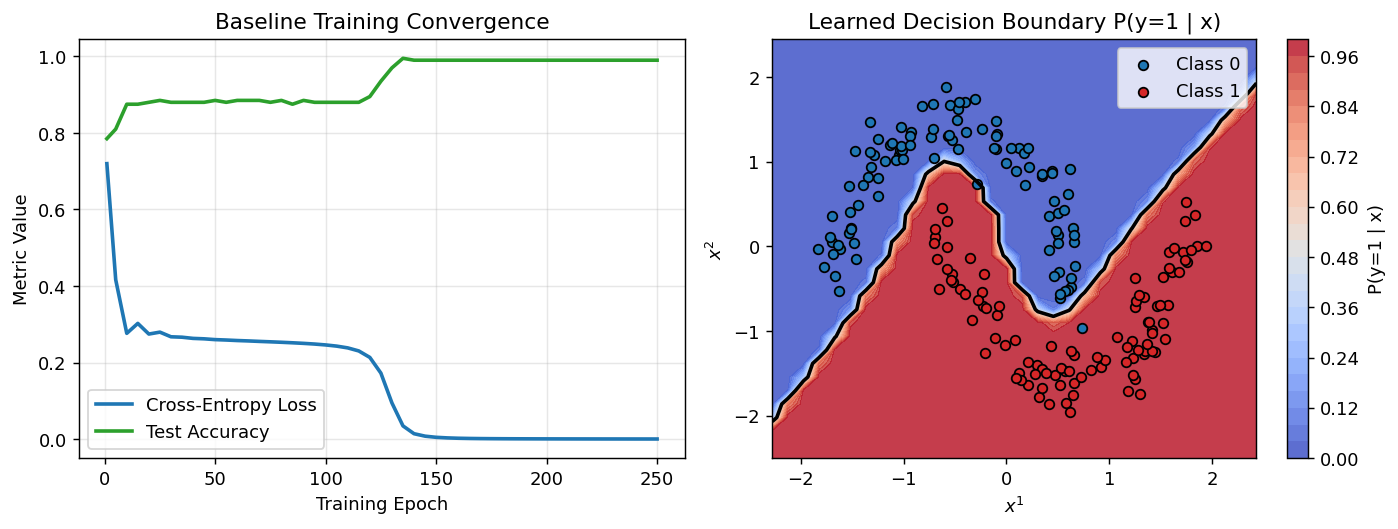

In [2]:
model = MoonsMLP(layer_dims=(2, 5, 10, 15, 10, 2), activation="tanh", seed=42)
total_params = sum(p.numel() for p in model.parameters())
print(f"MoonsMLP Architecture: {model.layer_dims} | Total parameters P = {total_params}")

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.015)

checkpoints = {0: copy.deepcopy(model.state_dict())}
history = {"epoch": [], "loss": [], "train_acc": [], "test_acc": []}

for epoch in range(1, 251):
    optimizer.zero_grad()
    logits = model(X_train)
    loss = criterion(logits, y_train)
    loss.backward()
    optimizer.step()

    if epoch % 5 == 0 or epoch == 1:
        with torch.no_grad():
            tr_acc = (logits.argmax(dim=-1) == y_train).float().mean().item()
            te_acc = (model(X_test).argmax(dim=-1) == y_test).float().mean().item()
        history["epoch"].append(epoch)
        history["loss"].append(loss.item())
        history["train_acc"].append(tr_acc)
        history["test_acc"].append(te_acc)

    if epoch in [25, 80, 250]:
        checkpoints[epoch] = copy.deepcopy(model.state_dict())

print(f"Final Epoch 250 | Cross-Entropy Loss: {history['loss'][-1]:.4f} | Train Acc: {history['train_acc'][-1]:.3f} | Test Acc: {history['test_acc'][-1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(history["epoch"], history["loss"], lw=2, color="#1f77b4", label="Cross-Entropy Loss")
axes[0].plot(history["epoch"], history["test_acc"], lw=2, color="#2ca02c", label="Test Accuracy")
axes[0].set_xlabel("Training Epoch")
axes[0].set_ylabel("Metric Value")
axes[0].set_title("Baseline Training Convergence")
axes[0].legend()
axes[0].grid(alpha=0.3)

with torch.no_grad():
    probs_grid = torch.softmax(model(grid_pts), dim=-1)[:, 1].reshape(xx.shape).numpy()

cf = axes[1].contourf(xx, yy, probs_grid, levels=25, cmap="coolwarm", alpha=0.85)
axes[1].contour(xx, yy, probs_grid, levels=[0.5], colors="k", linewidths=2.0)
axes[1].scatter(X_test[y_test == 0, 0], X_test[y_test == 0, 1], c="#1f77b4", edgecolors="k", s=28, label="Class 0")
axes[1].scatter(X_test[y_test == 1, 0], X_test[y_test == 1, 1], c="#d62728", edgecolors="k", s=28, label="Class 1")
axes[1].set_title("Learned Decision Boundary P(y=1 | x)")
axes[1].set_xlabel("$x^1$")
axes[1].set_ylabel("$x^2$")
axes[1].legend(loc="upper right")
plt.colorbar(cf, ax=axes[1], label="P(y=1 | x)")
plt.tight_layout()
plt.show()

## 2. Layerwise Volume Magnification $\sqrt{\det g^{(\ell)}(x)}$ and Anisotropy $\lambda_1 / \lambda_2$
We evaluate $g^{(\ell)}_{ij}(x)$ across all five layers $\ell \in \{1, 2, 3, 4, 5\}$ on the 2D grid. Notice how the trained network concentrates high volume expansion ($\sqrt{\det g^{(\ell)}}$) and extreme directional stretching ($\lambda_1/\lambda_2$) along the nonlinear decision boundary separating the two moons, confirming **Zavatone-Veth et al. (2023)**.

Layer    Width    Median Vol      Max Vol         Median Cond (l1/l2) 
--------------------------------------------------------------------
l = 1    d = 5    0.2651          1.2096          4.15                
l = 2    d = 10   0.3057          4.6523          10.43               
l = 3    d = 15   0.5322          17.9995         17.14               
l = 4    d = 10   0.1614          43.1118         146.20              
l = 5    d = 2    0.1129          40.6741         15385.30            


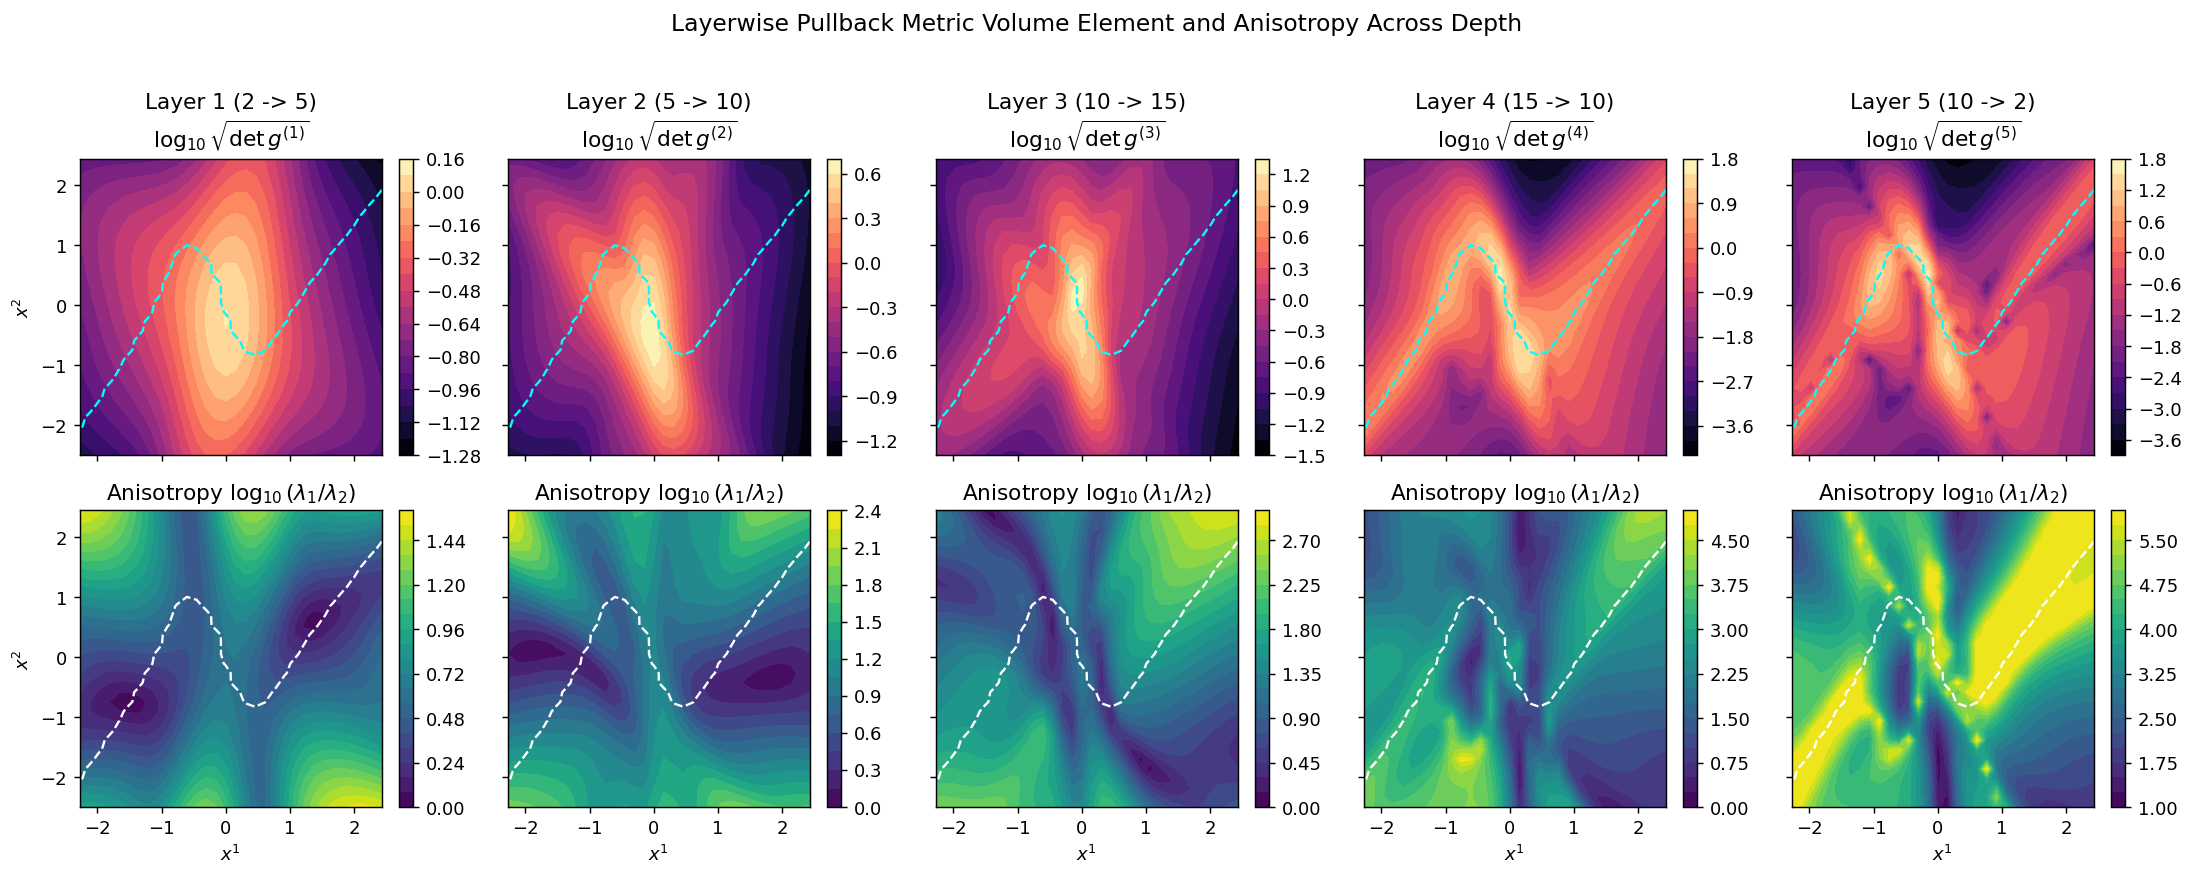

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(17, 6.6), sharex=True, sharey=True)
layer_titles = [
    "Layer 1 (2 -> 5)",
    "Layer 2 (5 -> 10)",
    "Layer 3 (10 -> 15)",
    "Layer 4 (15 -> 10)",
    "Layer 5 (10 -> 2)",
]

summary_rows = []
for idx, l_idx in enumerate(range(1, 6)):
    g_grid = compute_layer_pullback_metric(model, grid_pts, layer_idx=l_idx, metric_mode="euclidean", eps=1e-7)
    vol = compute_volume_element(g_grid).detach().numpy().reshape(xx.shape)
    evals, _, cond = compute_metric_spectrum(g_grid)
    log_vol = np.log10(np.clip(vol, 1e-6, None))
    log_cond = np.log10(np.clip(cond.detach().numpy().reshape(xx.shape), 1.0, 1e6))

    summary_rows.append((l_idx, model.layer_dims[l_idx], float(np.median(vol)), float(np.max(vol)), float(np.median(cond.detach().numpy()))))

    im0 = axes[0, idx].contourf(xx, yy, log_vol, levels=20, cmap="magma")
    axes[0, idx].contour(xx, yy, probs_grid, levels=[0.5], colors="cyan", linewidths=1.3, linestyles="--")
    axes[0, idx].set_title(f"{layer_titles[idx]}\n$\log_{{10}}\sqrt{{\det g^{{({l_idx})}}}}$")
    plt.colorbar(im0, ax=axes[0, idx], fraction=0.046)

    im1 = axes[1, idx].contourf(xx, yy, log_cond, levels=20, cmap="viridis")
    axes[1, idx].contour(xx, yy, probs_grid, levels=[0.5], colors="white", linewidths=1.3, linestyles="--")
    axes[1, idx].set_title(f"Anisotropy $\log_{{10}}(\lambda_1 / \lambda_2)$")
    axes[1, idx].set_xlabel("$x^1$")
    plt.colorbar(im1, ax=axes[1, idx], fraction=0.046)

axes[0, 0].set_ylabel("$x^2$")
axes[1, 0].set_ylabel("$x^2$")
plt.suptitle("Layerwise Pullback Metric Volume Element and Anisotropy Across Depth", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

print(f"{'Layer':<8} {'Width':<8} {'Median Vol':<15} {'Max Vol':<15} {'Median Cond (l1/l2)':<20}")
print("-" * 68)
for row in summary_rows:
    print(f"l = {row[0]:<4d} d = {row[1]:<4d} {row[2]:<15.4f} {row[3]:<15.4f} {row[4]:<20.2f}")

## 3. Tissot Indicatrices (Metric Tensor Ellipses) & Singular Foliation Compression
To visualize the full $2 \times 2$ tensor field $g^{(\ell)}_{ij}(x)$ rather than just scalar invariants, we draw **Tissot ellipses** whose semi-axes align with the eigenvectors of $g^{(\ell)}(x)$ scaled by $\sqrt{\lambda_1}, \sqrt{\lambda_2}$. As predicted by **Benfenati & Marta (2023)**, deeper layers compress tangent vectors parallel to the decision boundary (forming 1D equivalence leaves) while strongly amplifying vectors orthogonal to the boundary.

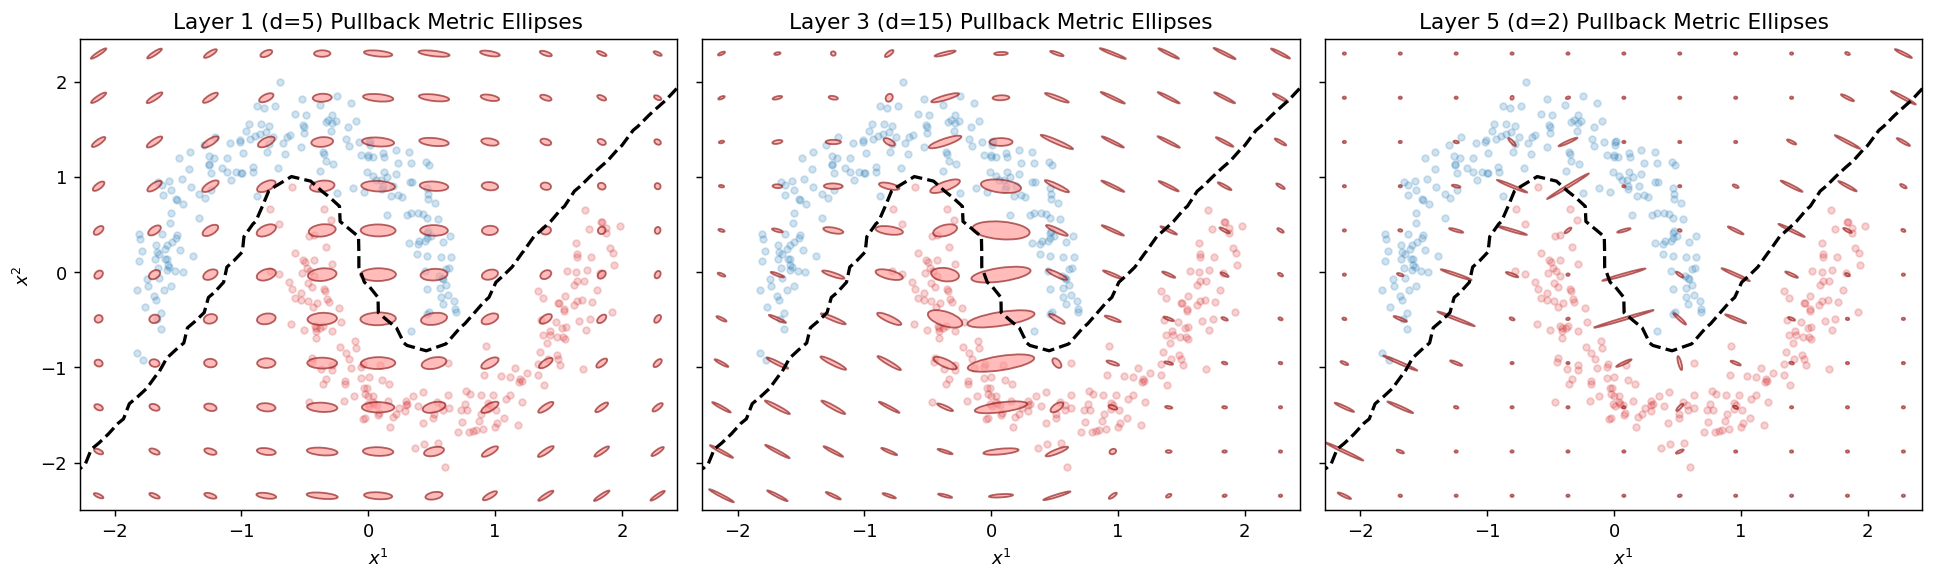

In [4]:
_, _, coarse_pts = make_evaluation_grid(X_train, n_grid=11, padding=0.3)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharex=True, sharey=True)

for ax, l_idx in zip(axes, [1, 3, 5]):
    g_c = compute_layer_pullback_metric(model, coarse_pts, layer_idx=l_idx, metric_mode="euclidean", eps=1e-6)
    evals, evecs, _ = compute_metric_spectrum(g_c)
    evals_np = np.sqrt(evals.detach().numpy())
    scale = 0.24 / (np.percentile(evals_np[:, 0], 90) + 1e-8)

    ax.contour(xx, yy, probs_grid, levels=[0.5], colors="k", linewidths=1.8, linestyles="--")
    ax.scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1], c="#1f77b4", alpha=0.20, s=14)
    ax.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1], c="#d62728", alpha=0.20, s=14)

    pts_np = coarse_pts.detach().numpy()
    evecs_np = evecs.detach().numpy()
    for i in range(len(pts_np)):
        v1 = evecs_np[i, :, 0]
        angle = np.degrees(np.arctan2(v1[1], v1[0]))
        w = max(evals_np[i, 0] * scale, 0.025)
        h = max(evals_np[i, 1] * scale, 0.025)
        ell = Ellipse(xy=pts_np[i], width=w, height=h, angle=angle, edgecolor="#8c1515", facecolor="#ff9896", alpha=0.65, lw=1.0)
        ax.add_patch(ell)

    ax.set_title(f"Layer {l_idx} (d={model.layer_dims[l_idx]}) Pullback Metric Ellipses")
    ax.set_xlabel("$x^1$")
axes[0].set_ylabel("$x^2$")
plt.tight_layout()
plt.show()

## 4. Symmetry Breaking Across Training Epochs & Activation Smoothness Comparison
We compare the pullback volume field $\sqrt{\det g^{(4)}(x)}$ from random initialization ($t=0$) through convergence ($t=250$), and compare smooth activations (`tanh`, `gelu`, `softplus`) against piecewise-linear `relu`.

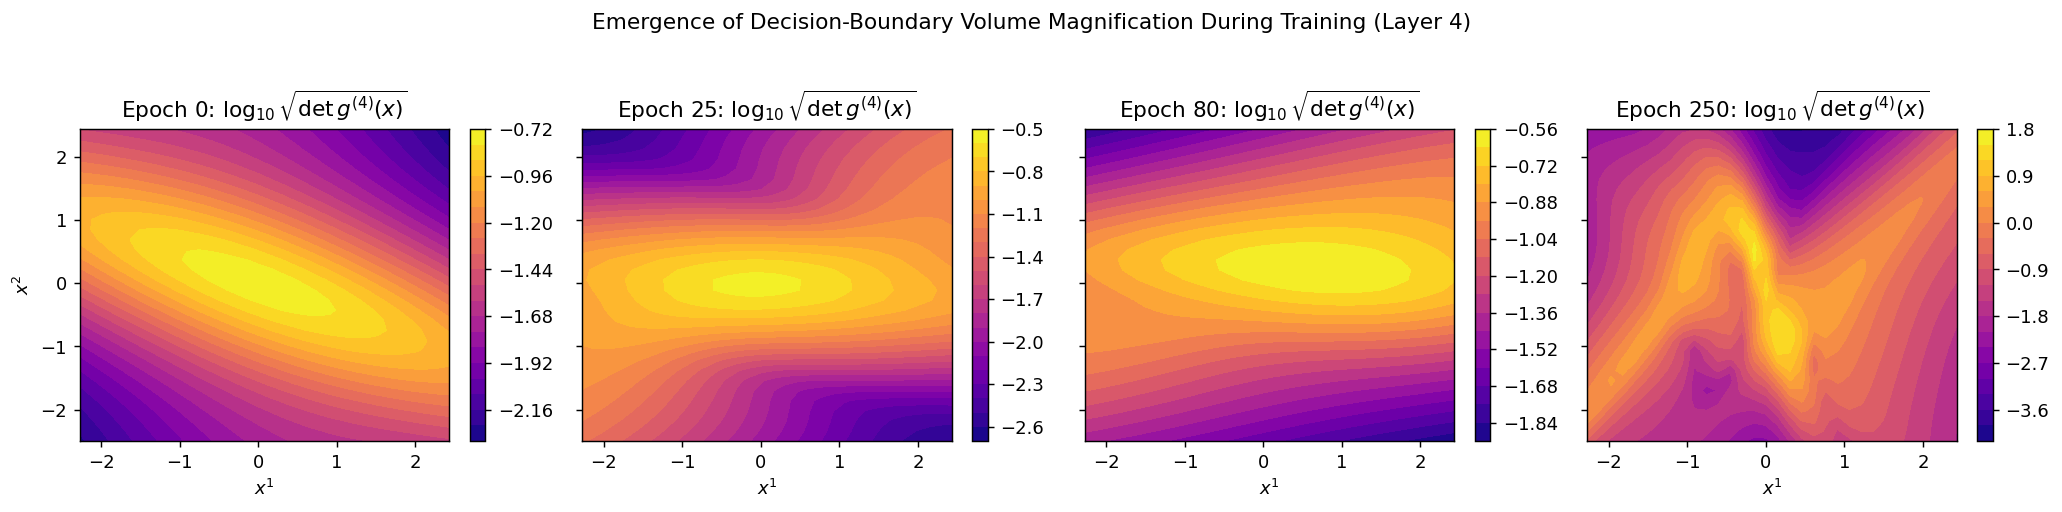

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharex=True, sharey=True)
probe_model = MoonsMLP(layer_dims=(2, 5, 10, 15, 10, 2), activation="tanh", seed=42)

for ax, ep in zip(axes, [0, 25, 80, 250]):
    probe_model.load_state_dict(checkpoints[ep])
    g4 = compute_layer_pullback_metric(probe_model, grid_pts, layer_idx=4, metric_mode="euclidean", eps=1e-7)
    vol4 = np.log10(compute_volume_element(g4).detach().numpy().reshape(xx.shape) + 1e-7)
    im = ax.contourf(xx, yy, vol4, levels=20, cmap="plasma")
    ax.set_title(f"Epoch {ep}: $\log_{{10}}\sqrt{{\det g^{{(4)}}(x)}}$")
    ax.set_xlabel("$x^1$")
    plt.colorbar(im, ax=ax, fraction=0.046)
axes[0].set_ylabel("$x^2$")
plt.suptitle("Emergence of Decision-Boundary Volume Magnification During Training (Layer 4)", y=1.03)
plt.tight_layout()
plt.show()